# CBC Test Diagnos

## Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter('ignore')

In [ ]:
df = pd.read_csv('/content/cbc_multilabel_dataset_20k_v2.csv')

## Data Analysis

In [ ]:
df.head(5)

,Gender,HGB,HCT,WBC,LYM#,LYM%,NE#,NE%,PLT,Anemia,Viral,Bacterial,Class
0,F,10.3,31.9,5.65,1.26,22.3,2.96,52.4,423,1,0,0,anemia
1,M,8.8,26.6,8.25,2.27,27.5,5.45,66.1,283,1,0,0,anemia
2,F,14.9,44.3,12.40,1.25,10.1,9.94,80.2,239,0,0,1,bacterial
3,F,13.0,36.5,16.39,1.09,6.7,13.43,82.0,220,0,0,1,bacterial
4,M,10.8,31.7,6.12,1.92,31.3,4.01,65.6,251,1,0,0,anemia


In [ ]:
df.shape

(20000, 13)

In [ ]:
df.size

260000

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Gender     20000 non-null  object 
 1   HGB        20000 non-null  float64
 2   HCT        20000 non-null  float64
 3   WBC        20000 non-null  float64
 4   LYM#       20000 non-null  float64
 5   LYM%       20000 non-null  float64
 6   NE#        20000 non-null  float64
 7   NE%        20000 non-null  float64
 8   PLT        20000 non-null  int64  
 9   Anemia     20000 non-null  int64  
 10  Viral      20000 non-null  int64  
 11  Bacterial  20000 non-null  int64  
 12  Class      20000 non-null  object 
dtypes: float64(7), int64(4), object(2)
memory usage: 2.0+ MB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HGB,20000.0,12.319095,2.594980,5.00,10.000,13.00,14.60,17.00
HCT,20000.0,36.956155,7.880539,15.00,30.075,39.10,43.70,53.90
WBC,20000.0,10.021448,5.182674,2.00,6.210,8.49,13.42,31.80
LYM#,20000.0,2.404255,1.073508,0.26,1.650,2.27,3.02,7.81
LYM%,20000.0,29.770555,16.174571,3.00,15.200,29.10,42.30,75.00
NE#,20000.0,6.677767,4.772734,0.51,3.000,4.61,10.08,24.38
NE%,20000.0,60.656660,16.025706,18.30,46.900,59.90,75.90,94.00
PLT,20000.0,269.495950,68.776854,120.00,222.000,269.00,316.00,450.00
Anemia,20000.0,0.475000,0.499387,0.00,0.000,0.00,1.00,1.00
Viral,20000.0,0.319150,0.466159,0.00,0.000,0.00,1.00,1.00


In [ ]:
df.isnull().sum()

,0
Gender,0
HGB,0
HCT,0
WBC,0
LYM#,0
LYM%,0
NE#,0
NE%,0
PLT,0
Anemia,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
Gender,2
HGB,119
HCT,369
WBC,2278
LYM#,630
LYM%,697
NE#,1987
NE%,695
PLT,331
Anemia,2


## Data Visualization

<Figure size 1200x600 with 0 Axes>

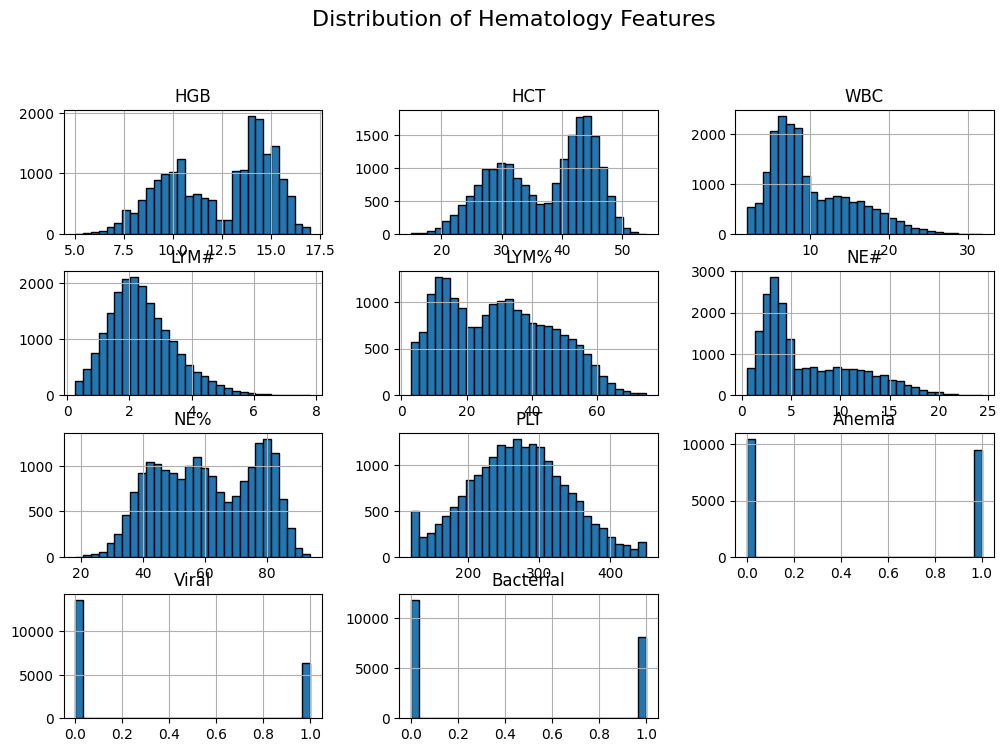

In [ ]:
# Distribution of Numeric Features

plt.figure(figsize=(12, 6))
df.hist(figsize=(12, 10), bins=30, edgecolor='black', layout=(5, 3))
plt.suptitle('Distribution of Hematology Features', fontsize=16)
plt.show()

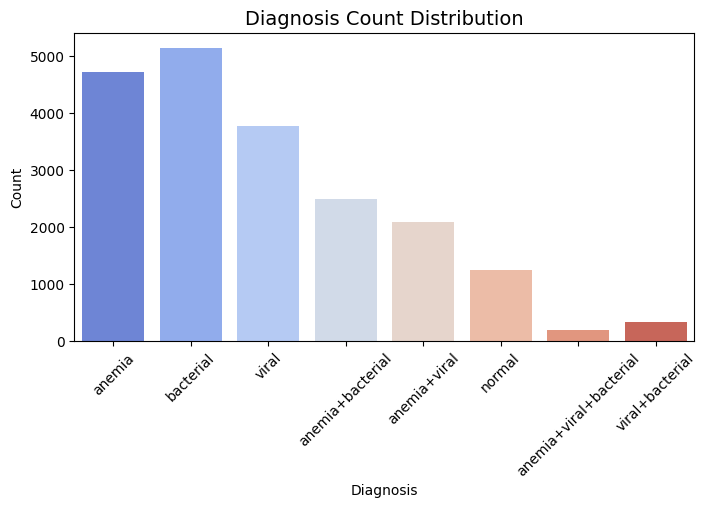

In [ ]:
# Count of Diagnoses (Target Variable)

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Class', palette='coolwarm')
plt.xticks(rotation=45)
plt.title('Diagnosis Count Distribution', fontsize=14)
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

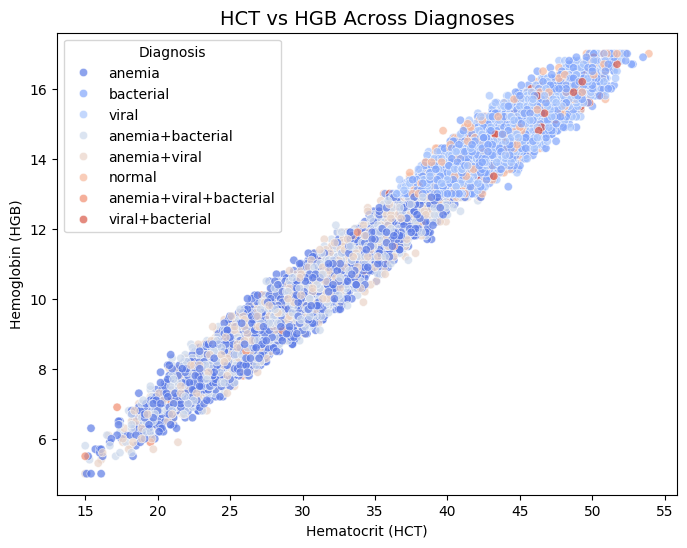

In [ ]:
# Scatterplot of HCT vs. HGB by Diagnosis

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='HCT', y='HGB', hue='Class', palette='coolwarm', alpha=0.7)
plt.title('HCT vs HGB Across Diagnoses', fontsize=14)
plt.xlabel('Hematocrit (HCT)')
plt.ylabel('Hemoglobin (HGB)')
plt.legend(title='Diagnosis')
plt.show()

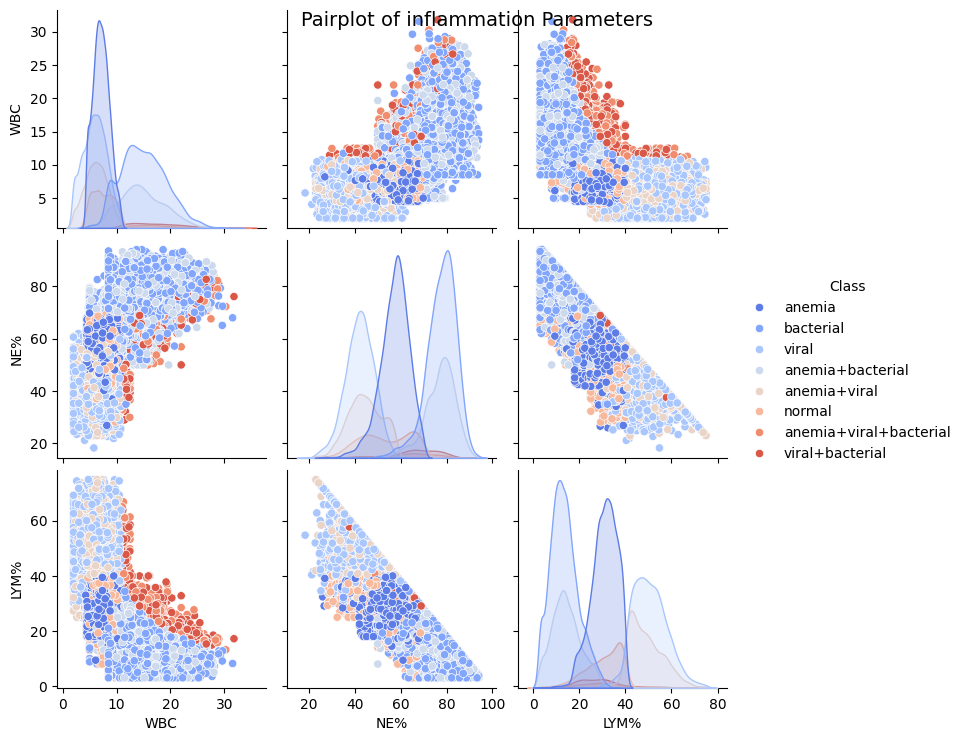

In [ ]:
# Pairplot of Important Blood Parameters

sns.pairplot(df, vars=['WBC', 'NE%' , 'LYM%'], hue='Class', palette='coolwarm')
plt.suptitle('Pairplot of inflammation Parameters', fontsize=14)
plt.show()

## Data Preprocessing

In [ ]:
# drop unwanted feature
X = df.drop('Class',axis=1)
X = df.drop('Anemia',axis=1)
X = df.drop('Viral',axis=1)
X = df.drop('Bacterial',axis=1)

y = df['Class']

# Safely encode categorical 'Gender' object to numeric
if X['Gender'].dtype == 'object':
    X['Gender'] = X['Gender'].map({'M': 1, 'F': 0})

# Drop target and identity helper columns if they are present in the features
columns_to_drop = ['Class', 'Anemia', 'Viral', 'Bacterial']
X = X.drop(columns=[col for col in columns_to_drop if col in X_train.columns], errors='ignore')

# Drop any lingering rows with NaN values just in case
X = X.fillna(0)


In [ ]:
# Label Encoder
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_label = label_encoder.fit_transform(y)

In [ ]:
# display the classes
print(label_encoder.classes_)
y_label

['anemia' 'anemia+bacterial' 'anemia+viral' 'anemia+viral+bacterial'
 'bacterial' 'normal' 'viral' 'viral+bacterial']


array([0, 0, 4, ..., 4, 0, 6], shape=(20000,))

In [ ]:
# Train test and split
from sklearn.model_selection import train_test_split

X_train, X_test,y_train,y_test = train_test_split(X,y_label,test_size =0.2,random_state =45,stratify=y_label)

## Model Building

## Testing different type of models

### Import classifier

In [ ]:
# Random forest
from sklearn.ensemble import RandomForestClassifier
clfRan= RandomForestClassifier(n_estimators=5, random_state=45)

In [ ]:
# KNN
from sklearn.neighbors import KNeighborsClassifier
clfKN= KNeighborsClassifier(n_neighbors=5)

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
clfLo= LogisticRegression(random_state=45)

In [ ]:
# Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier
clfGB= GradientBoostingClassifier(n_estimators=5, random_state=45)

### 1. Rnadom Forest model

In [ ]:
# Fit the Random forest classifier
clfRan.fit(X_train, y_train)

# Predict the test data
y_pred = clfRan.predict(X_test)

# Check accuracy
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.998

In [ ]:
# test Random forest model with external CBC sample
new_patient_data = {
    'Gender': [0],
    'HGB':[14.0],
    'HCT': [37.6],
    'WBC': [3.09],
    'LYM#': [1.98],
    'LYM%': [64.2],
    'NE#': [0.84],
    'NE%': [27.2],
    'PLT': [224]
}

# Convert the sample to a DataFrame
new_sample_df = pd.DataFrame(new_patient_data)

predicted_class_encoded= clfRan.predict(new_sample_df)

predicted_diagnosis = label_encoder.inverse_transform(predicted_class_encoded)

print(f"Predicted Class Code: {predicted_class_encoded[0]}")
print(f"Predicted Diagnosis: {predicted_diagnosis[0]}")


Predicted Class Code: 6
Predicted Diagnosis: viral


### 2. KNN model

In [ ]:
# Fit the KNN classifier
clfKN.fit(X_train, y_train)

# Predict the test data
y_pred = clfKN.predict(X_test)

# check accuracy
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9025

In [ ]:
# test KNN model with external CBC sample
new_patient_data = {
    'Gender': [0],
    'HGB':[14.0],
    'HCT': [37.6],
    'WBC': [3.09],
    'LYM#': [1.98],
    'LYM%': [64.2],
    'NE#': [0.84],
    'NE%': [27.2],
    'PLT': [224]
}

# Convert the sample to a DataFrame
new_sample_df = pd.DataFrame(new_patient_data)

predicted_class_encoded= clfKN.predict(new_sample_df)

predicted_diagnosis = label_encoder.inverse_transform(predicted_class_encoded)

print(f"Predicted Class Code: {predicted_class_encoded[0]}")
print(f"Predicted Diagnosis: {predicted_diagnosis[0]}")

Predicted Class Code: 6
Predicted Diagnosis: viral


### 3. logistic regression model

In [ ]:
# Fit the logistic regression classifier
clfLo.fit(X_train, y_train)

# Predict the test data
y_pred = clfLo.predict(X_test)

# check accuracy
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.858

In [ ]:
# test logistic regression model with external CBC sample
new_patient_data = {
    'Gender': [0],
    'HGB':[14.0],
    'HCT': [37.6],
    'WBC': [3.09],
    'LYM#': [1.98],
    'LYM%': [64.2],
    'NE#': [0.84],
    'NE%': [27.2],
    'PLT': [224]
}

# Convert the sample to a DataFrame
new_sample_df = pd.DataFrame(new_patient_data)

predicted_class_encoded= clfLo.predict(new_sample_df)

predicted_diagnosis = label_encoder.inverse_transform(predicted_class_encoded)

print(f"Predicted Class Code: {predicted_class_encoded[0]}")
print(f"Predicted Diagnosis: {predicted_diagnosis[0]}")

Predicted Class Code: 6
Predicted Diagnosis: viral


### 4. Gradient Boosting model

In [ ]:
# Fit the Gradient Boosting Classifier
clfGB.fit(X_train, y_train)

# Predict the test data
y_pred = clfGB.predict(X_test)

# check accuracy
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.989

In [ ]:
# test Gradient Boosting model with external CBC sample
new_patient_data = {
    'Gender': [0],
    'HGB':[14.0],
    'HCT': [37.6],
    'WBC': [3.09],
    'LYM#': [1.98],
    'LYM%': [64.2],
    'NE#': [0.84],
    'NE%': [27.2],
    'PLT': [224]
}

# Convert the sample to a DataFrame
new_sample_df = pd.DataFrame(new_patient_data)

predicted_class_encoded= clfGB.predict(new_sample_df)

predicted_diagnosis = label_encoder.inverse_transform(predicted_class_encoded)

print(f"Predicted Class Code: {predicted_class_encoded[0]}")
print(f"Predicted Diagnosis: {predicted_diagnosis[0]}")

Predicted Class Code: 6
Predicted Diagnosis: viral


# Saving Ranadom Forest Model

In [ ]:
import joblib
model_file_name = 'saved_model.joblib'

# Save the scikit-learn StackingClassifier model
joblib.dump(clfRan, model_file_name)

# Load the model back
model = joblib.load(model_file_name)

In [ ]:
import joblib
import pandas as pd
import numpy as np

# 1. Load the saved stacking model
loaded_model = joblib.load('saved_model.joblib')

# 2. Define a new sample representing a patient's CBC test results
# Note: This dictionary must contain the exact feature names and order as the training set X
new_patient_data = {
    'Gender': [0],
    'HGB':[15.3],
    'HCT': [36.0],
    'WBC': [10.9],
    'LYM#': [4.49],
    'LYM%': [69.0],
    'NE#': [5.28],
    'NE%': [26.0],
    'PLT': [329]
}

# Convert the sample to a DataFrame
new_sample_df = pd.DataFrame(new_patient_data)

# 3. Predict the numerical class
predicted_class_encoded = loaded_model.predict(new_sample_df)

# 4. Decode the class index back to the diagnosis string
predicted_diagnosis = label_encoder.inverse_transform(predicted_class_encoded)

print(f"Predicted Class Code: {predicted_class_encoded[0]}")
print(f"Predicted Diagnosis: {predicted_diagnosis[0]}")

Predicted Class Code: 6
Predicted Diagnosis: viral
